# Experimentation
---
In this notebook, we experiment with different functino settings, base data, files, concepts and visualisations. The goal is to find the best way to convey the findings of our research, both in terms of visualisation, but also in terms of metrics which are used for the communication.

In [2]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS

***
## Display raw data

In [4]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 4,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          4 (every 90°), sample every 1 m up to 24 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 24 samples
       6-12    m: 24 samples
      12-18    m: 24 samples
      18-24    m: 24 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.18    5.85     5.97     5.85
mean     6.74    6.62     6.43     6.29
std      4.03    4.19     4.18     3.52
min      0.00    0.00     0.00     0.00
25%      4.58    4.12     3.73     3.72
50%      6.18    5.85     5.97     5.85
75%      8.46    8.78     7.66     8.25
max     19.38   21.36    20.26    17.16

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kilns [

/var/folders/br/770tdjgs0s11gdcqp7p99g_00000gn/T/ipykernel_24142/1337812026.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


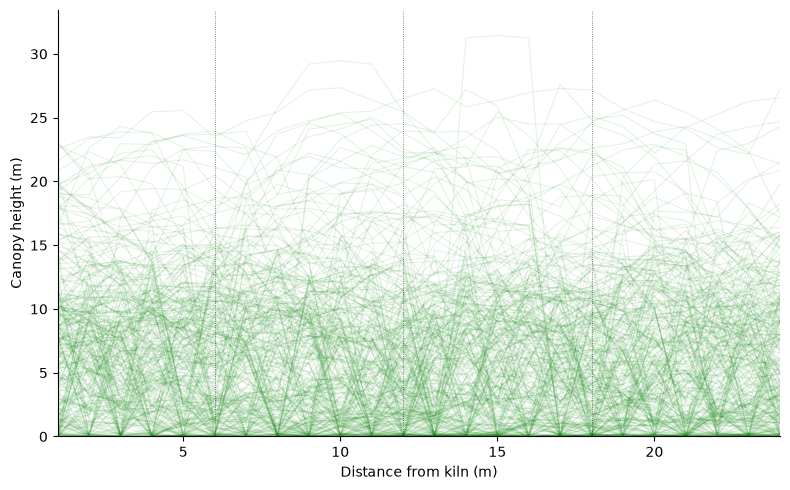

In [21]:
samples = pd.read_csv("results/merged_dem_rays4_step1_ring6x4/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24)]

fig, ax = plt.subplots(figsize=(8,5))

for _, line in samples.groupby(["kiln_id", "ray"]):
    ax.plot(line["distance"], line["value"], color="green", alpha=0.1, lw=0.8)

for _, outer in rings[:-1]:
    ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

ax.set_xlim(1,24)
ax.set_ylim(0, max(samples["value"])+2)
ax.set_xlabel("Distance from kiln (m)")
ax.set_ylabel("Canopy height (m)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("results/merged_dem_rays4_step1_ring6x4/ray_profiles_raw.png", dpi=400)